## وارد کردن کتابخانه‌ها

In [1]:
import sdv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

## خواندن دیتاست

In [2]:
df = pd.read_csv("data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


## تثبیت Seed برای تکرارپذیری

In [3]:
import random
random.seed(42)
np.random.seed(42)

In [4]:
# Detect metadata
metadata = sdv.metadata.Metadata.detect_from_dataframes(
    data={'comedian': df}
)

# Create synthesizer
synthesizer = sdv.single_table.GaussianCopulaSynthesizer(
    metadata
)

# Fit the synthesizer
synthesizer.fit({'comedian': df})

# Generate 100 synthetic rows
synthetic_data = synthesizer.sample(
    num_rows=100
)['comedian']

# Combine original and synthetic data
df_augmented = pd.concat(
    [df, synthetic_data],
    ignore_index=True
)

display(df_augmented)

C:\Users\em\Desktop\fintech\assignment\FINAL PROJECT\files\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
...,...,...,...,...,...
108,41,10,4,USA,YES
109,21,5,5,USA,YES
110,21,10,8,USA,NO
111,43,18,8,UK,YES



با GaussianCopulaSynthesizer صد ردیف مصنوعی تولید و به ۱۳ ردیف اصلی اضافه شد و دیتاست ۱۱۳ ردیفی ساخته شد. ردیف‌های مصنوعی از توزیع همان ۱۳ ردیف نمونه‌برداری شده‌اند، پس حجم داده زیاد می‌شود ولی اطلاعات تازه‌ای به آن اضافه نمی‌شود.

## بررسی کیفیت داده مصنوعی

In [5]:
print("Missing values:\n", df_augmented.isnull().sum())
print("\nExperience > Age:", (df_augmented["Experience"] > df_augmented["Age"]).sum())
print("Rank out of original range:",
      (~df_augmented["Rank"].between(df["Rank"].min(), df["Rank"].max())).sum())
display(df_augmented.describe())

Missing values:
 Age            0
Experience     0
Rank           0
Nationality    0
Go             0
dtype: int64

Experience > Age: 0
Rank out of original range: 0


,Age,Experience,Rank
count,113.000000,113.000000,113.000000
mean,35.451327,10.734513,6.849558
std,13.956560,5.429775,1.793944
min,18.000000,3.000000,4.000000
25%,24.000000,5.000000,5.000000
50%,34.000000,10.000000,7.000000
75%,43.000000,15.000000,8.000000
max,66.000000,21.000000,9.000000


## تبدیل ستون‌های متنی به عددی

Nationality به صورت UK=0، USA=1 و N=2 و ستون Go به صورت YES=1 و NO=0  درخت فقط با آستانه‌گذاری روی مقدار ویژگی‌ها تقسیم می‌کند.

In [6]:
df_augmented['Nationality'] = df_augmented['Nationality'].map({
    'UK': 0,
    'USA': 1,
    'N': 2
})

df_augmented['Go'] = df_augmented['Go'].map({
    'YES': 1,
    'NO': 0
})

display(df_augmented)

,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
...,...,...,...,...,...
108,41,10,4,1,1
109,21,5,5,1,1
110,21,10,8,1,0
111,43,18,8,0,1


## جدا کردن ویژگی‌ها و متغیر هدف


In [7]:
features = ["Age", "Experience", "Rank", "Nationality"]
X = df_augmented[features]
y = df_augmented["Go"]

print(y.value_counts())

Go
1    74
0    39
Name: count, dtype: int64



در داده تقویت‌شده ۷۴ ردیف YES و ۳۹ ردیف NO داریم (حدود ۶۵٪ در برابر ۳۵٪). این نسبت به YES متمایل‌تر از داده اصلی (۷ از ۱۳) است، یعنی داده مصنوعی کمی نامتوازن‌تر از داده اصلی تولید شده است.

## آموزش درخت تصمیم Gini


Train accuracy: 1.0
Depth: 12 | Leaves: 48


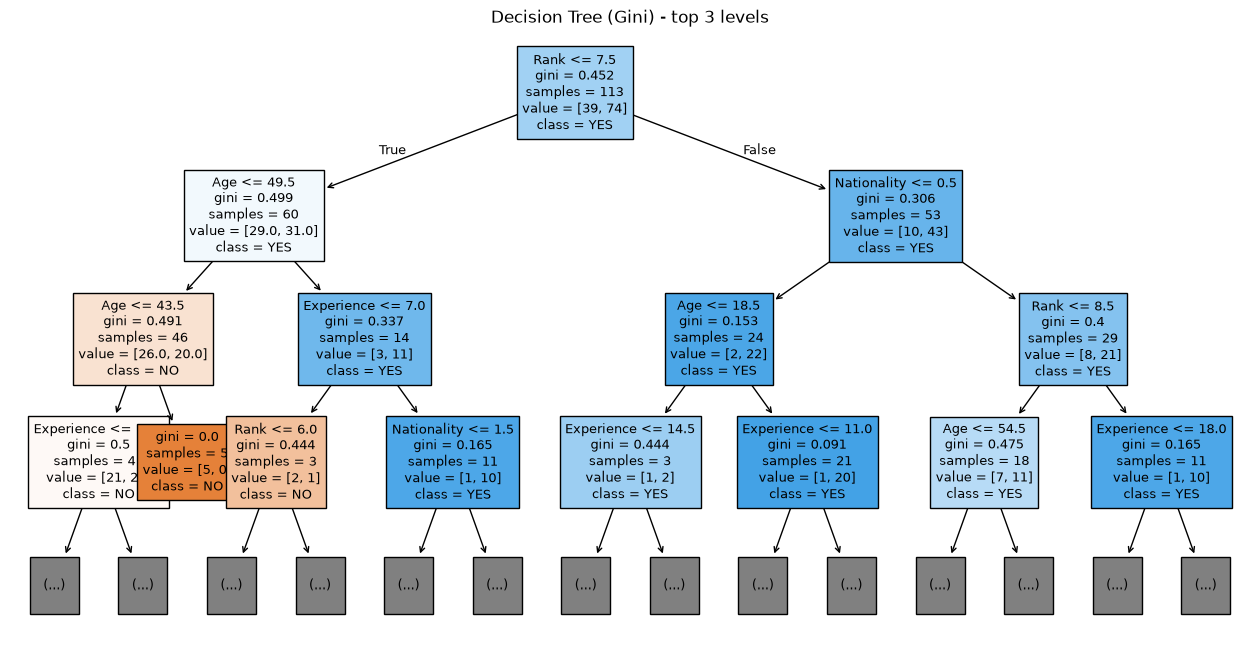

In [8]:
dt_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_gini.fit(X, y)

print("Train accuracy:", accuracy_score(y, dt_gini.predict(X)))
print("Depth:", dt_gini.get_depth(), "| Leaves:", dt_gini.get_n_leaves())

plt.figure(figsize=(16, 8))
plot_tree(dt_gini, feature_names=features, class_names=["NO", "YES"],
          filled=True, max_depth=3, fontsize=9)
plt.title("Decision Tree (Gini) - top 3 levels")
plt.show()


درخت Gini به Accuracy آموزشی برابر ۱٫۰ با عمق ۱۲ و ۴۸ برگ رسید. دقت کامل روی داده آموزشی و تعداد زیاد برگ‌ها (نزدیک به ۴۲٪ تعداد ردیف‌ها) یعنی درخت داده را تقریباً حفظ کرده و دچار Overfitting شده است. نمودار فقط سه سطح اول را نشان می‌دهد و در آن، شاخه‌های بالایی از Rank شروع می‌شوند.

## آموزش درخت تصمیم Entropy 



Train accuracy: 1.0
Depth: 14 | Leaves: 47


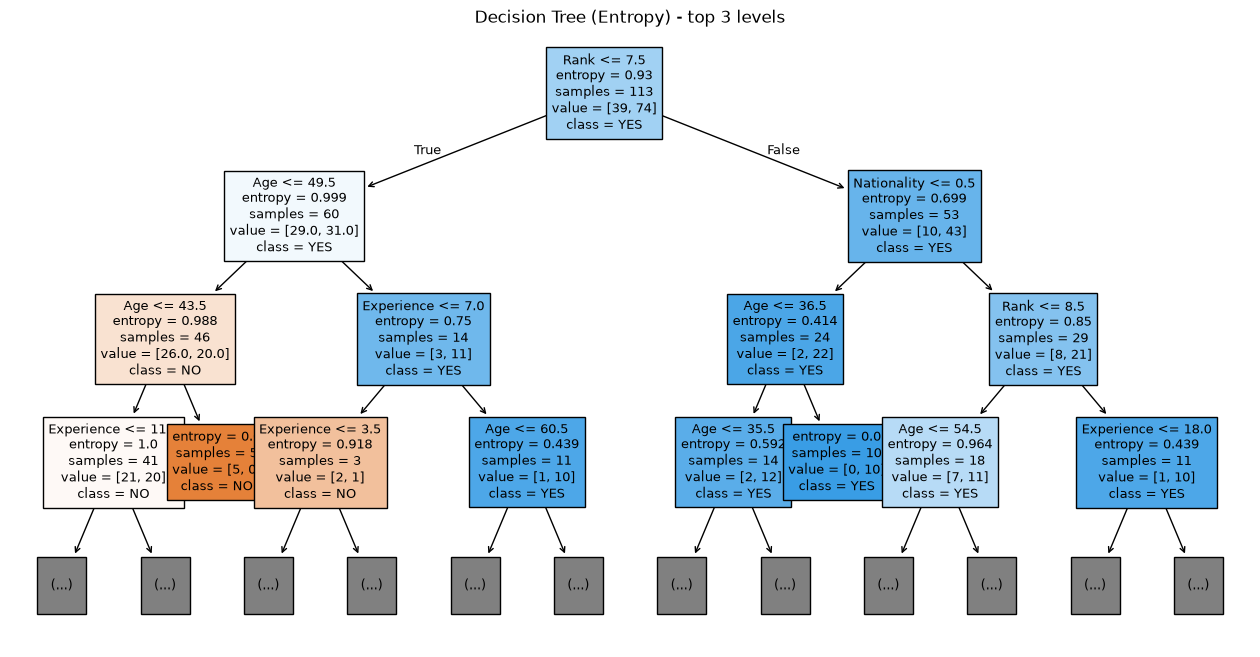

In [9]:
dt_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_entropy.fit(X, y)

print("Train accuracy:", accuracy_score(y, dt_entropy.predict(X)))
print("Depth:", dt_entropy.get_depth(), "| Leaves:", dt_entropy.get_n_leaves())

plt.figure(figsize=(16, 8))
plot_tree(dt_entropy, feature_names=features, class_names=["NO", "YES"],
          filled=True, max_depth=3, fontsize=9)
plt.title("Decision Tree (Entropy) - top 3 levels")
plt.show()

درخت Entropy هم Accuracy آموزشی ۱٫۰ دارد و عمق ۱۴ و ۴۷ برگ. ساختار سطح‌های بالا شبیه Gini است و فرق دو درخت فقط در شاخه‌های عمیق‌تر دیده می‌شود، چون هر دو معیار ناخالصی را کم می‌کنند و در این داده کوچک معمولاً تقسیم‌های مشابهی انتخاب می‌کنند.

## مقایسه ساختار و اهمیت ویژگی‌ها در Gini و Entropy

,Criterion,Train Accuracy,Depth,Leaves,Root Feature
0,gini,1.0,12,48,Rank
1,entropy,1.0,14,47,Rank


,Gini,Entropy
Age,0.476,0.424
Experience,0.295,0.361
Rank,0.191,0.140
Nationality,0.038,0.075


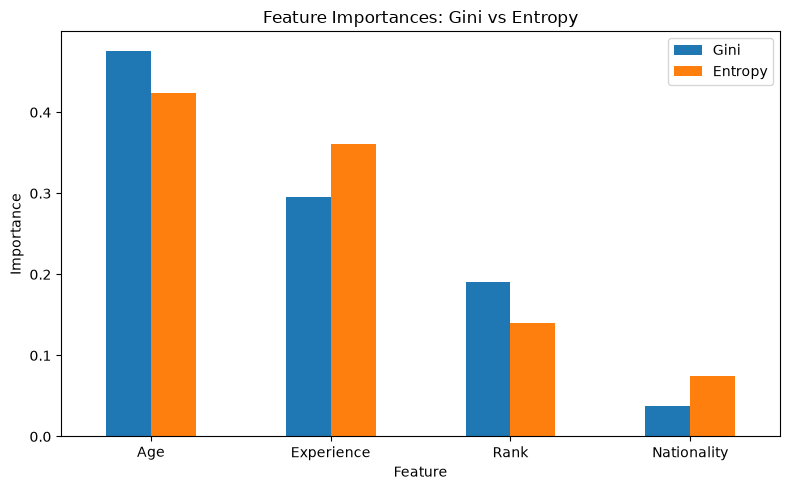

In [10]:
summary = pd.DataFrame({
    "Criterion": ["gini", "entropy"],
    "Train Accuracy": [accuracy_score(y, dt_gini.predict(X)),
                       accuracy_score(y, dt_entropy.predict(X))],
    "Depth": [dt_gini.get_depth(), dt_entropy.get_depth()],
    "Leaves": [dt_gini.get_n_leaves(), dt_entropy.get_n_leaves()],
    "Root Feature": [features[dt_gini.tree_.feature[0]],
                     features[dt_entropy.tree_.feature[0]]],
}).round(3)
display(summary)

importances = pd.DataFrame({
    "Gini": dt_gini.feature_importances_,
    "Entropy": dt_entropy.feature_importances_
}, index=features).round(3)
display(importances)

ax = importances.plot(kind="bar", figsize=(8, 5))
ax.set_title("Feature Importances: Gini vs Entropy")
ax.set_xlabel("Feature")
ax.set_ylabel("Importance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



ویژگی ریشه در هر دو مدل Rank است و Accuracy آموزشی هر دو ۱٫۰ است، پس تفاوت اصلی در عمق (۱۲ در برابر ۱۴) و تعداد برگ‌ها (۴۸ در برابر ۴۷) است. در نمودار، Age در هر دو مدل مهم‌ترین ویژگی است (۰٫۴۷۶ در Gini و ۰٫۴۲۴ در Entropy) و Nationality کم‌اهمیت‌ترین. Entropy وزن بیشتری به Experience و Nationality می‌دهد و وزن کمتری به Rank و Age.

نکته: Rank ریشه است ولی Age بیشترین اهمیت را دارد. دلیل این است که اهمیت ویژگی از مجموع کاهش ناخالصی در همه تقسیم‌ها به دست می‌آید و Age به‌عنوان ویژگی پیوسته با مقدارهای متنوع در تقسیم‌های بیشتری شرکت می‌کند. اختلاف بین دو معیار جزئی است و نمی‌توان یکی را قطعاً بهتر دانست.

In [11]:
nat_map = {"UK": 0, "USA": 1, "N": 2}
go_map = {"YES": 1, "NO": 0}

syn = synthetic_data.copy()
syn["Nationality"] = syn["Nationality"].map(nat_map)
syn["Go"] = syn["Go"].map(go_map)

orig = df.copy()
orig["Nationality"] = orig["Nationality"].map(nat_map)
orig["Go"] = orig["Go"].map(go_map)

for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, random_state=42)
    m.fit(syn[features], syn["Go"])
    acc = accuracy_score(orig["Go"], m.predict(orig[features]))
    print(f"{crit}: accuracy on 13 original rows = {acc:.3f}")

gini: accuracy on 13 original rows = 0.615
entropy: accuracy on 13 original rows = 0.538


##  آموزش روی داده مصنوعی و آزمون روی داده اصلی

مدل‌ها فقط روی ۱۰۰ ردیف مصنوعی آموزش دیدند و روی ۱۳ ردیف واقعی آزموده شدند تا ارزیابی روی داده دیده‌شده نباشد. Gini به Accuracy برابر ۰٫۶۱۵ (۸ از ۱۳) و Entropy به ۰٫۵۳۸ (۷ از ۱۳) رسید. چون ۷ از ۱۳ ردیف اصلی YES است، پیش‌بینی همیشه YES هم به ۰٫۵۳۸ می‌رسد؛ بنابراین Entropy از حدس ثابت بهتر نیست و Gini فقط یک ردیف بیشتر درست پیش‌بینی کرده که از نظر آماری معنادار نیست. نتیجه این است که تقویت داده با SDV توان تعمیم مدل را بهبود نداده، چون داده مصنوعی اطلاعات تازه‌ای نداشته است.